# Sale Price of Homes Prediction Model

---
embed-resources: true
echo: false
---

## Introduction

The purpose of this report is to present the development of a model that estimates the sale prices of homes given features of the home such as size, number of bathrooms, etc, in Iowa. 

The primary goal of this model is to serve as a competitor to Zillow's 'Zestimate' and to minimize errors that these predictions will make.

## Methods

Below are the various imports that were used towards building this model. 

In [ ]:
# imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_percentage_error
def proportion_within_threshold(y_true, y_pred, threshold=0.20):
    return np.mean((np.abs(y_pred - y_true) / y_true) <= threshold)
from sklearn.metrics import ConfusionMatrixDisplay


from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

<u>**These are general imports for visualizations, muting warnings, and accessing the pandas library, as well as exporting the model:**</u>
```
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from joblib import dump
import warnings
warnings.filterwarnings('ignore')
```

<u>**These imports are related to model building and scoring:**</u>
```
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_percentage_error
def proportion_within_threshold(y_true, y_pred, threshold=0.20):
    return np.mean((np.abs(y_pred - y_true) / y_true) <= threshold)

```

<u>**These imports were used for model preprocessing:**</u>
```
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```

### Data

To achieve the goal for building this model, we used data provided in the following parquet files:

- Training Data: housing-train.parquet

- Test Data: swing-test.parquet

The original source for this data originally comes from the following publication: 

- De Cock, D. (2011). Ames, Iowa: Alternative to the Boston housing data as an end of semester regression project. Journal of Statistics Education, 19(3). https://doi.org/10.1080/10691898.2011.11889627

However, this data from this paper has become a standard dataset in the machine learning community, and thus is also available via Kaggle: 

- https://www.kaggle.com/datasets/marcopale/housing

<u>**Data Dictionary for reference**</u>

**`SalePrice`**

- `[int64]` Sale price in USD.

**`Order`**

- `[int64]` Observation number.

**`PID`**

- `[int64]` Parcel identification number - can be used with city web site for parcel review.

**`MS SubClass`**

- `[int64]` Identifies the type of dwelling involved in the sale.

**`MS Zoning`**

- `[object]` Identifies the general zoning classification of the sale.

**`Lot Frontage`**

- `[float64]` Linear feet of street connected to property.

**`Lot Area`**

- `[int64]` Lot size in square feet.

**`Street`**

- `[object]` Type of road access to property.

**`Alley`**

- `[object]` Type of alley access to property.

**`Lot Shape`**

- `[object]` General shape of property.

**`Land Contour`**

- `[object]` Flatness of the property.

**`Utilities`**

- `[object]` Type of utilities available.

**`Lot Config`**

- `[object]` Lot configuration.

**`Land Slope`**

- `[object]` Slope of property.

**`Neighborhood`**

- `[object]` Physical locations within Ames city limits (map available).

**`Condition 1`**

- `[object]` Proximity to various conditions.

**`Condition 2`**

- `[object]` Proximity to various conditions (if more than one is present).

**`Bldg Type`**

- `[object]` Type of dwelling.

**`House Style`**

- `[object]` Style of dwelling.

**`Overall Qual`**

- `[int64]` Rates the overall material and finish of the house.

**`Overall Cond`**

- `[int64]` Rates the overall condition of the house.

**`Year Built`**

- `[int64]` Original construction date.

**`Year Remod/Add`**

- `[int64]` Remodel date (same as construction date if no remodeling or additions).

**`Roof Style`**

- `[object]` Type of roof.

**`Roof Matl`**

- `[object]` Roof material.

**`Exterior 1st`**

- `[object]` Exterior covering on house.

**`Exterior 2nd`**

- `[object]` Exterior covering on house (if more than one material).

**`Mas Vnr Type`**

- `[object]` Masonry veneer type.

**`Mas Vnr Area`**

- `[float64]` Masonry veneer area in square feet.

**`Exter Qual`**

- `[object]` Evaluates the quality of the material on the exterior.

**`Exter Cond`**

- `[object]` Evaluates the present condition of the material on the exterior.

**`Foundation`**

- `[object]` Type of foundation.

**`Bsmt Qual`**

- `[object]` Evaluates the height of the basement.

**`Bsmt Cond`**

- `[object]` Evaluates the general condition of the basement.

**`Bsmt Exposure`**

- `[object]` Refers to walkout or garden level walls.

**`BsmtFin Type 1`**

- `[object]` Rating of basement finished area.

**`BsmtFin SF 1`**

- `[float64]` Type 1 finished square feet.

**`BsmtFin Type 2`**

- `[object]` Rating of basement finished area (if multiple types).

**`BsmtFin SF 2`**

- `[float64]` Type 2 finished square feet.

**`Bsmt Unf SF`**

- `[float64]` Unfinished square feet of basement area.

**`Total Bsmt SF`**

- `[float64]` Total square feet of basement area.

**`Heating`**

- `[object]` Type of heating.

**`Heating QC`**

- `[object]` Heating quality and condition.

**`Central Air`**

- `[object]` Central air conditioning.

**`Electrical`**

- `[object]` Electrical system.

**`1st Flr SF`**

- `[int64]` First Floor square feet.

**`2nd Flr SF`**

- `[int64]` Second floor square feet.

**`Low Qual Fin SF`**

- `[int64]` Low quality finished square feet (all floors).

**`Gr Liv Area`**

- `[int64]` Above grade (ground) living area square feet.

**`Bsmt Full Bath`**

- `[float64]` Basement full bathrooms.

**`Bsmt Half Bath`**

- `[float64]` Basement half bathrooms.

**`Full Bath`**

- `[int64]` Full bathrooms above grade.

**`Half Bath`**

- `[int64]` Half baths above grade.

**`Bedroom AbvGr`**

- `[int64]` Bedrooms above grade (does not include basement bedrooms).

**`Kitchen AbvGr`**

- `[int64]` Kitchens above grade.

**`Kitchen Qual`**

- `[object]` Kitchen quality.

**`TotRms AbvGrd`**

- `[int64]` Total rooms above grade (does not include bathrooms).

**`Functional`**

- `[object]` Home functionality (Assume typical unless deductions are warranted).

**`Fireplaces`**

- `[int64]` Number of fireplaces.

**`Fireplace Qu`**

- `[object]` Fireplace quality.

**`Garage Type`**

- `[object]` Garage location.

**`Garage Yr Blt`**

- `[float64]` Year garage was built.

**`Garage Finish`**

- `[object]` Interior finish of the garage.

**`Garage Cars`**

- `[float64]` Size of garage in car capacity.

**`Garage Area`**

- `[float64]` Size of garage in square feet.

**`Garage Qual`**

- `[object]` Garage quality.

**`Garage Cond`**

- `[object]` Garage condition.

**`Paved Drive`**

- `[object]` Paved driveway.

**`Wood Deck SF`**

- `[int64]` Wood deck area in square feet.

**`Open Porch SF`**

- `[int64]` Open porch area in square feet.

**`Enclosed Porch`**

- `[int64]` Enclosed porch area in square feet.

**`3Ssn Porch`**

- `[int64]` Three season porch area in square feet.

**`Screen Porch`**

- `[int64]` Screen porch area in square feet.

**`Pool Area`**

- `[int64]` Pool area in square feet.

**`Pool QC`**

- `[object]` Pool quality.

**`Fence`**

- `[object]` Fence quality.

**`Misc Feature`**

- `[object]` Miscellaneous feature not covered in other categories.

**`Misc Val`**

- `[int64]` Value of miscellaneous feature.

**`Mo Sold`**

- `[int64]` Month Sold (MM).

**`Yr Sold`**

- `[int64]` Year Sold (YYYY).

**`Sale Type`**

- `[object]` Type of sale.

**`Sale Condition`**

- `[object]` Condition of sale.

In [23]:
# load data
housing_train = pd.read_parquet(
    "https://lab.cs307.org/housing/data/housing-train.parquet"
)
housing_test = pd.read_parquet(
    "https://lab.cs307.org/housing/data/housing-test.parquet"
)

<u>**First few rows of training data**</u>

In [24]:
housing_train.head(5)

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,635,535175030,20,RL,80.0,9600,Pave,None,Reg,Lvl,...,0,None,MnPrv,None,0,4,2009,WD,Normal,139000
1,2169,908102160,85,RL,75.0,9825,Pave,None,Reg,Low,...,0,None,None,Shed,450,8,2007,WD,Abnorml,118500
2,2097,906340080,60,RL,77.0,9965,Pave,None,Reg,Lvl,...,0,None,None,None,0,10,2007,New,Partial,383970
3,1446,907201060,80,RL,65.0,8385,Pave,None,Reg,Lvl,...,0,None,None,None,0,11,2008,WD,Normal,149900
4,2857,909256020,50,RL,51.0,6191,Pave,None,Reg,Lvl,...,0,None,None,None,0,11,2006,WD,Normal,112000


<u>**First few rows of testing data**</u>

In [25]:
housing_test.head(5)

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1067,528172080,20,RL,92.0,10845,Pave,None,IR1,Lvl,...,0,None,None,None,0,6,2008,WD,Normal,284000
1,2598,535376100,30,RL,60.0,5400,Pave,None,Reg,Lvl,...,0,None,None,None,0,12,2006,WD,Abnorml,108480
2,18,527258010,20,RL,88.0,11394,Pave,None,Reg,Lvl,...,0,None,None,None,0,6,2010,New,Partial,394432
3,2700,904100090,90,RL,120.0,11136,Pave,None,Reg,Lvl,...,0,None,None,None,0,7,2006,WD,Normal,150000
4,291,909177100,90,RH,60.0,7200,Pave,Pave,Reg,Lvl,...,0,None,None,Shed,500,2,2010,WD,Normal,160000


<u>**General summary statistics of data**</u>

In the training data, there are 1875 samples and 81 different features.

In [26]:
housing_train.describe().transpose().rename(columns = {'25%' : '25th percentile', '50%' : '50th percentile', '75%' : '75th percentile'})

,count,mean,std,min,25th percentile,50th percentile,75th percentile,max
Order,1875.0,1.456020e+03,8.471829e+02,1.0,723.5,1464.0,2181.5,2928.0
PID,1875.0,7.149438e+08,1.887383e+08,526301100.0,528456185.0,535453160.0,907135045.0,924152030.0
MS SubClass,1875.0,5.646933e+01,4.178244e+01,20.0,20.0,50.0,70.0,190.0
Lot Frontage,1573.0,6.937699e+01,2.341081e+01,21.0,59.0,68.0,80.0,313.0
Lot Area,1875.0,1.013923e+04,8.632001e+03,1300.0,7417.5,9316.0,11381.5,215245.0
Overall Qual,1875.0,6.080533e+00,1.403008e+00,1.0,5.0,6.0,7.0,10.0
Overall Cond,1875.0,5.558400e+00,1.081116e+00,1.0,5.0,5.0,6.0,9.0
Year Built,1875.0,1.971739e+03,3.000235e+01,1872.0,1954.0,1974.0,2001.0,2010.0
Year Remod/Add,1875.0,1.984571e+03,2.070465e+01,1950.0,1966.0,1993.0,2004.0,2010.0
Mas Vnr Area,1860.0,9.868978e+01,1.730845e+02,0.0,0.0,0.0,154.5,1224.0


<u>**Various Visualizations of the Data**</u>

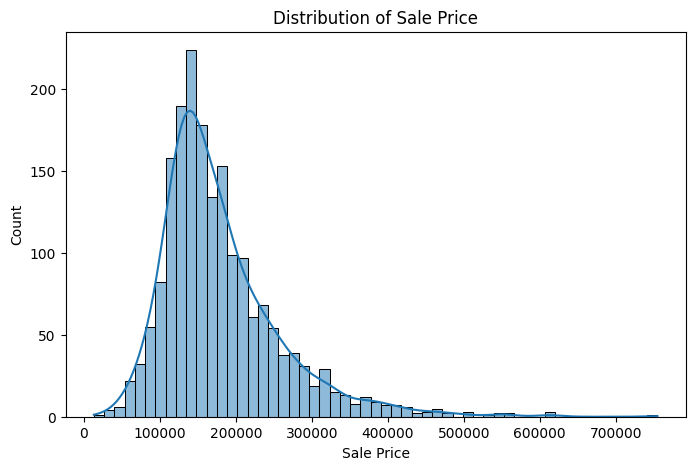

In [27]:
plt.figure(figsize = (8,5))
sns.histplot(housing_train["SalePrice"], kde = True)
plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.show()

Figure 1. Histogram and kernel density estimate of home sale prices in the dataset. The distribution is right-skewed, indicating that most houses sell in the $120,000–$220,000 range, with fewer high-priced outliers extending above $400,000. 

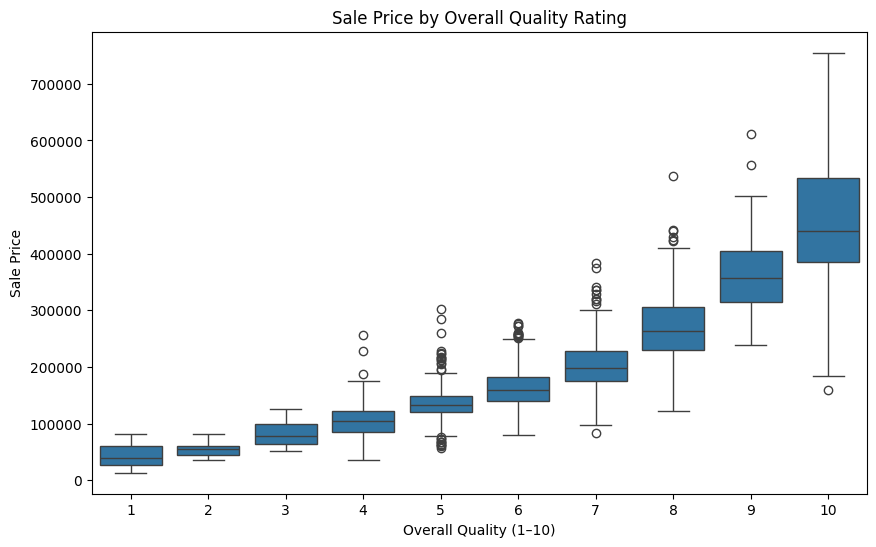

In [28]:
plt.figure(figsize = (10,6))
sns.boxplot(data = housing_train, x = "Overall Qual", y = "SalePrice")
plt.title("Sale Price by Overall Quality Rating")
plt.xlabel("Overall Quality (1–10)")
plt.ylabel("Sale Price")
plt.show()

Figure 2. Boxplot of sale price across quality ratings (1–10). Home prices increase sharply with higher Overall Qual, showing strong positive association between perceived building quality and market value. Variability also widens at higher quality levels, indicating that luxury homes span a broader price range.

### Models

To prepare for model development, the data was first split into training and testing sets for both predictors (X) and the response variable (y). The feature matrix (X) includes both numerical and categorical variables.

For model preprocessing, two separate pipelines were defined using the `StandardScaler` and `OneHotEncoder` transformers. The numerical pipeline imputes missing values with the mean and standardizes the features, while the categorical pipeline imputes missing values with the most frequent category and encodes them as binary indicator variables. These two pipelines were combined using a `ColumnTransformer`, ensuring all preprocessing steps are applied consistently across the dataset. The preprocessor was then fit and transformed on the training data prior to modeling.

```
X_train = housing_train.drop("SalePrice", axis=1)
y_train = housing_train["SalePrice"]

X_test = housing_test.drop("SalePrice", axis=1)
y_test = housing_test["SalePrice"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = 'most_frequent'),
                                        OneHotEncoder(handle_unknown = 'ignore', sparse_output = False))

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features)
)
```

In [29]:

X_train = housing_train.drop("SalePrice", axis=1)
y_train = housing_train["SalePrice"]

X_test = housing_test.drop("SalePrice", axis=1)
y_test = housing_test["SalePrice"]

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
categorical_transformer = make_pipeline(SimpleImputer(strategy = 'most_frequent'),
                                        OneHotEncoder(handle_unknown = 'ignore', sparse_output = False))

numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include = ['object', 'category']).columns

preprocessor = make_column_transformer(
    (numeric_transformer, numeric_features),
    (categorical_transformer, categorical_features)
)

To model housing sale price estimates, a HistGradientBoostingClassifier was implemented as a base estimator, chosen for its superior speed to GradientBoostingclassifier, and superb ability to handle larger datasets effectively. The base models predicted sale prices were refined using GridSearchCV. 

```
hgb = HistGradientBoostingRegressor()
pipeline = make_pipeline(preprocessor, hgb)

param_grid = {
    'histgradientboostingregressor__learning_rate': [0.03, 0.05, 0.07],
    'histgradientboostingregressor__max_depth': [8, 10, 12],
    'histgradientboostingregressor__max_leaf_nodes': [60, 80, 100],
    'histgradientboostingregressor__min_samples_leaf': [5, 10, 20],
    'histgradientboostingregressor__l2_regularization': [0.001, 0.01, 0.1],
}

model = GridSearchCV(
    estimator = pipeline,
    param_grid = param_grid,
    scoring = 'neg_mean_absolute_percentage_error',  
    cv = 3,
    verbose = 2,
    n_jobs = -1
)

model.fit(X_train, y_train)
```

In [30]:
hgb = HistGradientBoostingRegressor()
pipeline = make_pipeline(preprocessor, hgb)

param_grid = {
    'histgradientboostingregressor__learning_rate': [0.03, 0.05, 0.07],
    'histgradientboostingregressor__max_depth': [8, 10, 12],
    'histgradientboostingregressor__max_leaf_nodes': [60, 80, 100],
    'histgradientboostingregressor__min_samples_leaf': [5, 10, 20],
    'histgradientboostingregressor__l2_regularization': [0.001, 0.01, 0.1],
}

model = GridSearchCV(
    estimator = pipeline,
    param_grid = param_grid,
    scoring = 'neg_mean_absolute_percentage_error',  
    cv = 3,
    verbose = 2,
    n_jobs = -1
)

model.fit(X_train, y_train)

Fitting 3 folds for each of 243 candidates, totalling 729 fits


,estimator,Pipeline(step...Regressor())])
,param_grid,"{'histgradientboostingregressor__l2_regularization': [0.001, 0.01, ...], 'histgradientboostingregressor__learning_rate': [0.03, 0.05, ...], 'histgradientboostingregressor__max_depth': [8, 10, ...], 'histgradientboostingregressor__max_leaf_nodes': [60, 80, ...], ...}"
,scoring,'neg_mean_absolute_percentage_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('pipeline-1', ...), ('pipeline-2', ...)]"


## Results

The model's performance was evaluated on the test data using the mean absolute percentage error and scored using a function that measures the proportion of predictions that are within 20% of the true value. 

In [36]:
print('Mean Absolute Percentage error: ', mean_absolute_percentage_error(y_test, model.predict(X_test)))
print('Proportion Within the Threshold: ', proportion_within_threshold(y_test, model.predict(X_test)))

Mean Absolute Percentage error:  0.08954511325445029
Proportion Within the Threshold:  0.9253731343283582


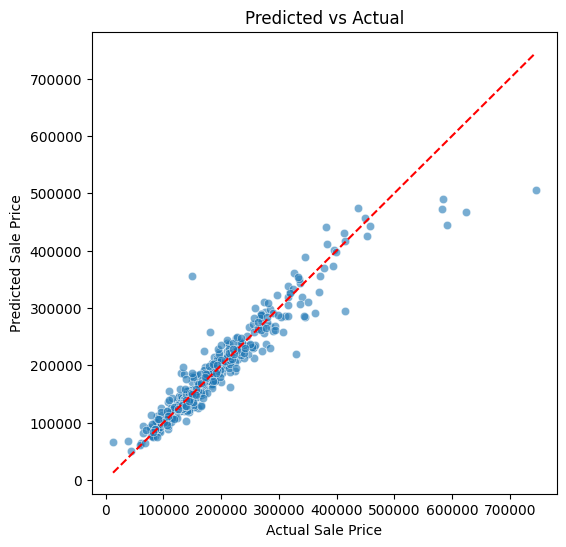

In [40]:
plt.figure(figsize=(6,6))
sns.scatterplot(x= y_test, y= model.predict(X_test), alpha = 0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Predicted vs Actual")
plt.show()

Figure 3. Scatter plot comparing predicted home sale prices to actual sale prices using the HistGradientBoostingRegressor. Each point represents a property in the test set. The red dashed 45° reference line indicates perfect prediction. Most points cluster near the line, suggesting strong predictive accuracy, though some divergence for higher-priced homes indicates increasing error at the upper end of the market.

## Discussion

### Would I deplot this model? 
I would NOT deploy this model at this point in time. While the model boasts a reasonably low mean absolute percentage error and high proportion of predictions within the true threshold, the overall predictive performance is not yet strong enough to justify immediate implementation. 

### Risks avoided by not using this model:
- Misleading probability estimates: Slight miscalibration or overfitting to training data could result in inaccurate predictions that would potentially mislead users.
- Limited generalizability: the model may not scale effectively to future years.

### Potential improvements
- Experiment with other model architectures such as Random Forests or XG Boosting methods
- Perform deeper hyperparameter optimization to improve performance without sacrificing GridSearchCV quality.

## Conclusion

Overall, the HistGradientBoostingRegressor shows promising behavior but is not yet production-ready. The model demonstrates a strong linear relationship between predicted and actual home prices and performs well across much of the value range; however, errors increase noticeably for higher-priced homes, and the current performance metrics suggest room for meaningful improvement. While the model has learned important market patterns, deploying it prematurely could create risks for end-users who rely on accurate price estimates for financial decision-making.

Moving forward, improving data preprocessing, tuning hyperparameters further, and testing alternative model architectures will likely enhance predictive accuracy and stability. With targeted improvements and additional validation, this model has the potential to become a highly effective competitor with Zestimate.